## MiniProject IDS
### Network Intrusion Detection System using the UNSW-NB15 dataset 

## Part A
### The problem and the data

Every day, a large number of network requests and flows enter organizations. To be able to understand and react to the different types of network traffic, machine learning can be used. One way to do this is by creating an Intrusion Detection System (IDS) that can classify network flows as either malicious or benign. However, to train such a system, we need a large amount of labeled data, which can be difficult to obtain.

A machine-learning-based IDS can be used in companies and could assist Security Operations Centre (SOC) analysts and network administrators in detecting potential cyberattacks and malicious activity and potentially blocking harmful requests before they enter the system.

However, false alerts in an intrusion detection system can be costly, as security analysts monitoring these alerts need to investigate and determine whether they are actual attacks or not. Too many false alerts can lead to alert fatigue, where analysts become overwhelmed by the number of warnings. This can reduce the effectiveness of the system, as frequent false alerts can cause people to lose trust in it and potentially overlook real attacks. 


In [36]:
# Run in your terminal once: pip install -r requirements_ids.txt
from pathlib import Path
import warnings, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, recall_score, f1_score, precision_score,
                             average_precision_score, confusion_matrix)
from sklearn.base import clone
from lime.lime_tabular import LimeTabularExplainer

warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
START = time.perf_counter()
DATA_DIR = Path('data')
RESULTS = Path('results'); RESULTS.mkdir(exist_ok=True)
SAMPLE_SIZE = None  # Set to None to use all available rows
print('Data directory:', DATA_DIR.resolve())

Data directory: /Users/natashadonner/Documents/LTU/D7084E/IntrusionDetectionSystem_MiniProject/data


### A1. Load and clean the CSV files

### Load the data

In [37]:
files = [DATA_DIR / "UNSW_NB15_training-set.csv",
         DATA_DIR / "UNSW_NB15_testing-set.csv"]

frames = []
for path in files:
    try:
        part = pd.read_csv(path, encoding="utf-8-sig", low_memory=False)
    except UnicodeDecodeError:
        part = pd.read_csv(path, encoding="latin1", low_memory=False)
    part.columns = part.columns.str.strip().str.lower()
    frames.append(part)

df = pd.concat(frames, ignore_index=True).drop(columns="id", errors="ignore")
n_raw = len(df)

# Class balance before cleaning
raw_counts = df["label"].value_counts().sort_index()
print("Normal flows (0):", raw_counts.get(0, 0))
print("Attack flows (1):", raw_counts.get(1, 0))
print("Attack share (%):", round(100 * df["label"].mean(), 2))


Normal flows (0): 93000
Attack flows (1): 164673
Attack share (%): 63.91


### Fix types and list the fetaures

In [38]:
# Convert the label to a number. errors="raise" stops the run if any value
# cannot be converted, so a corrupt label is never silently ignored.
df["label"] = pd.to_numeric(df["label"], errors="raise")

# The task is binary: every label must be 0 (normal) or 1 (attack).
assert df["label"].isin([0, 1]).all(), "Unexpected target labels"

# Store the label as an integer instead of a float (0 and 1, not 0.0 and 1.0).
df["label"] = df["label"].astype(int)

# Store as text, remove leading/trailing spaces (" DoS" -> "DoS"),
# and fill any missing value with "Unknown".
df["attack_cat"] = df["attack_cat"].astype("string").str.strip().fillna("Unknown")

# The three text features in UNSW-NB15. The "if c in df" check avoids an error
# if a column were missing.
categorical = [c for c in ["proto", "service", "state"] if c in df]
for c in categorical:
    # Same cleaning as attack_cat: text type, no extra spaces, no missing values.
    df[c] = df[c].astype("string").str.strip().fillna("Unknown")

# Every column that is not categorical, not the label and not the attack category.
numeric_cols = df.columns.difference(categorical + ["attack_cat", "label"])
for c in numeric_cols:
    # Convert to a number. errors="coerce" turns invalid values into NaN
    # instead of stopping; missing values are counted at the end of cleaning.
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Replace infinite values (e.g. from division by zero in rate features) with NaN,
# so they are treated as missing instead of as extremely large numbers.
df = df.replace([np.inf, -np.inf], np.nan)

# Everything except the two target columns is used as model input.
feature_cols = [c for c in df.columns if c not in ("label", "attack_cat")]

# Show all input features and their type, as documentation for the report.
print(f"Input features ({len(feature_cols)}):")
display(pd.DataFrame({
    "Feature": feature_cols,
    "Type": ["categorical" if c in categorical else "numeric" for c in feature_cols]
}))

# IP addresses, ports and timestamps identify hosts and sessions, not attack
# behaviour. The partitioned files should not contain them; stop if they do.
identifiers = ["srcip", "sport", "dstip", "dsport", "stime", "ltime"]
assert not any(c in df.columns for c in identifiers), "Identifier columns present"
print("No identifier columns (IP addresses, ports, timestamps) present.")

# Recorded so the report can show how cleaning changes the data.
print("\nRaw class counts:\n", df["label"].value_counts().sort_index())
print("Raw attack share (%):", round(100 * df["label"].mean(), 2))

Input features (42):


,Feature,Type
0,dur,numeric
1,proto,categorical
2,service,categorical
3,state,categorical
4,spkts,numeric
5,dpkts,numeric
6,sbytes,numeric
7,dbytes,numeric
8,rate,numeric
9,sttl,numeric


No identifier columns (IP addresses, ports, timestamps) present.

Raw class counts:
 label
0     93000
1    164673
Name: count, dtype: int64
Raw attack share (%): 63.91


### Inspect conflicts


In [39]:
grouped = df.groupby(feature_cols, dropna=False)
label_conf = grouped["label"].transform("nunique") > 1
cat_conf = (grouped["attack_cat"].transform("nunique") > 1) & ~label_conf

n_label_unique = df.loc[label_conf, feature_cols].drop_duplicates().shape[0]
print(f"Label conflicts (normal vs attack): {int(label_conf.sum())} rows, "
      f"{n_label_unique} unique flows")

combos = (df.loc[cat_conf].groupby(feature_cols, dropna=False)["attack_cat"]
            .agg(lambda s: "|".join(sorted(s.unique()))))
print(f"Category conflicts (attack vs attack): {int(cat_conf.sum())} rows, "
      f"{len(combos)} unique flows in {combos.nunique()} combinations")
display(combos.value_counts().rename("Flows").to_frame())

Label conflicts (normal vs attack): 1758 rows, 414 unique flows
Category conflicts (attack vs attack): 38642 rows, 2031 unique flows in 38 combinations


,Flows
attack_cat,
Analysis|Backdoor|DoS|Exploits|Fuzzers|Reconnaissance,906
Analysis|Backdoor|DoS|Exploits|Fuzzers,240
Analysis|Backdoor|DoS|Exploits|Fuzzers|Generic|Reconnaissance,228
Analysis|DoS|Exploits|Fuzzers|Reconnaissance,188
Backdoor|DoS|Exploits|Fuzzers|Reconnaissance,114
DoS|Exploits,96
Exploits|Reconnaissance,57
Exploits|Fuzzers,38
Backdoor|DoS|Exploits|Fuzzers|Generic|Reconnaissance,29


### Remove conflicts and duplicates

In [40]:
n_unique_before = df.drop_duplicates(subset=feature_cols).shape[0]
n_conf_unique = df.loc[label_conf | cat_conf, feature_cols].drop_duplicates().shape[0]
print(f"Conflicting flows removed: {n_conf_unique} "
      f"({100 * n_conf_unique / n_unique_before:.2f} % of unique flows)")

df = df[~(label_conf | cat_conf)]
df = df.drop_duplicates(subset=feature_cols).reset_index(drop=True)
print("Rows removed in total (conflicts + duplicates):", n_raw - len(df))

# Verify that no duplicates or conflicts remain
grouped = df.groupby(feature_cols, dropna=False)
assert df.duplicated(subset=feature_cols).sum() == 0, "Duplicates remain"
assert (grouped["label"].nunique() > 1).sum() == 0, "Label conflicts remain"
assert (grouped["attack_cat"].nunique() > 1).sum() == 0, "Category conflicts remain"
print("Verified: no duplicates or conflicts remain.")

Conflicting flows removed: 2445 (1.59 % of unique flows)
Rows removed in total (conflicts + duplicates): 106434
Verified: no duplicates or conflicts remain.


### Sample size


In [41]:
if SAMPLE_SIZE is not None and len(df) > SAMPLE_SIZE:
    df, _ = train_test_split(df, train_size=SAMPLE_SIZE,
                             stratify=df["attack_cat"], random_state=SEED)
    df = df.reset_index(drop=True)

print("Rows after cleaning:", len(df))
print("Input features:", len(feature_cols))
print("Class counts:\n", df["label"].value_counts().sort_index())
print("Class percentages:\n", (100 * df["label"].value_counts(normalize=True)).round(2))
display(df["attack_cat"].value_counts().rename("Flows").to_frame())
print("Missing feature values:", df[feature_cols].isna().sum().sum())

Rows after cleaning: 151239
Input features: 42
Class counts:
 label
0    85308
1    65931
Name: count, dtype: int64
Class percentages:
 label
0    56.41
1    43.59
Name: proportion, dtype: float64


,Flows
attack_cat,
Normal,85308
Exploits,25451
Fuzzers,18749
Reconnaissance,8419
Generic,7283
DoS,3624
Shellcode,1446
Analysis,450
Backdoor,350


Missing feature values: 0


### A2. Class balance and 60/20/20 split

Use 60% training, 20% validation, and 20% held-out testing, stratified by the binary label. Model choice is made on validation only. The test split is reserved until the final cell.

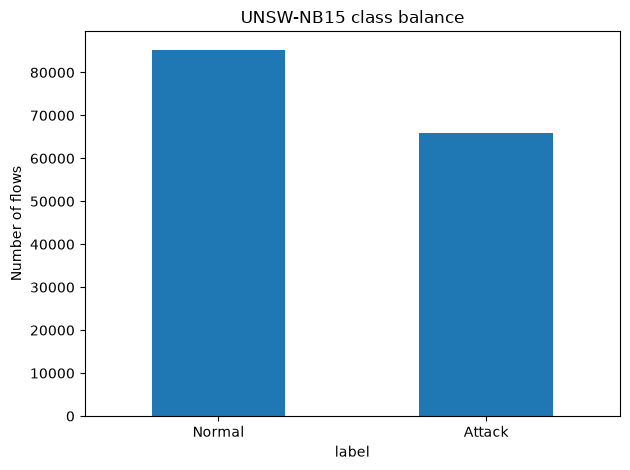

Train / validation / test: 90743 30248 30248


In [42]:
df["label"].map({0: "Normal", 1: "Attack"}).value_counts().reindex(["Normal", "Attack"]).plot.bar()
plt.title("UNSW-NB15 class balance")
plt.ylabel("Number of flows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

X = df.drop(columns=["label", "attack_cat"])
y = df["label"]
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)

cat_train = df.loc[X_train.index, "attack_cat"]
cat_test = df.loc[X_test.index, "attack_cat"]
print("Train / validation / test:", len(X_train), len(X_val), len(X_test))

In [43]:
cat_val = df.loc[X_val.index, "attack_cat"]

split_counts = pd.DataFrame({
    "Train": cat_train.value_counts(),
    "Validation": cat_val.value_counts(),
    "Test": cat_test.value_counts(),
}).fillna(0).astype(int)

split_counts["Total"] = split_counts.sum(axis=1)
split_counts = split_counts.sort_values("Total", ascending=False)

display(split_counts)

,Train,Validation,Test,Total
attack_cat,,,,
Normal,51185,17061,17062,85308
Exploits,15230,5043,5178,25451
Fuzzers,11231,3792,3726,18749
Reconnaissance,5083,1687,1649,8419
Generic,4370,1470,1443,7283
DoS,2191,721,712,3624
Shellcode,852,293,301,1446
Analysis,269,86,95,450
Backdoor,222,67,61,350


## Part B — Supervised models

In [44]:
numeric = X.select_dtypes(include="number").columns.tolist()
preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric),
    ("cat", Pipeline([
        ("missing", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical)
])

# Candidate settings are compared on validation data in section B1.
model_templates = {
    "Logistic Regression": Pipeline([
        ("prep", preprocess),
        ("scale", StandardScaler(with_mean=False)),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED))
    ]),
    "Decision Tree": Pipeline([
        ("prep", preprocess),
        ("clf", DecisionTreeClassifier(random_state=SEED))
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocess),
        ("clf", RandomForestClassifier(n_jobs=-1, random_state=SEED))
    ])
}

parameter_candidates = {
    "Logistic Regression": [{"clf__C": value} for value in [0.1, 1.0, 10.0]],
    "Decision Tree": [{"clf__max_depth": value} for value in [5, 10, None]],
    "Random Forest": [
        {"clf__n_estimators": n_estimators, "clf__max_depth": max_depth}
        for n_estimators in [100, 200]
        for max_depth in [10, None]
    ]
}

def scores(y_true, predicted, probability):
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(y_true, predicted),
            "Macro-F1": f1_score(y_true, predicted, average="macro", zero_division=0),
            "Attack recall": recall_score(y_true, predicted, zero_division=0),
            "PR-AUC (AP)": average_precision_score(y_true, probability),
            "FAR": fp / (fp + tn) if fp + tn else 0.0}

majority = int(y_train.mode()[0])
def baseline(y_true):
    pred = np.full(len(y_true), majority)
    return scores(y_true, pred, pred.astype(float))

print("Majority class:", majority)
display(pd.DataFrame({
    "Train": baseline(y_train),
    "Validation": baseline(y_val)
}).T.round(4))

Majority class: 0


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
Train,0.5641,0.3606,0.0,0.4359,0.0
Validation,0.5640,0.3606,0.0,0.4360,0.0


### B1. Train models and compare on validation

All preprocessing is learned using **training data only**. Validation scores determine which model is selected. A higher macro-F1 is better.

In [45]:
validation = {"Majority baseline": baseline(y_val)}
models = {}
selected_settings = {}
tuning_rows = []

for name, template in model_templates.items():
    best_score = -1.0
    best_model = None
    best_metrics = None
    best_params = None

    for params in parameter_candidates[name]:
        candidate = clone(template).set_params(**params)
        candidate.fit(X_train, y_train)
        prediction = candidate.predict(X_val)
        probability = candidate.predict_proba(X_val)[:, 1]
        metrics = scores(y_val, prediction, probability)
        tuning_rows.append({"Model": name, "Settings": str(params), **metrics})

        if metrics["Macro-F1"] > best_score:
            best_score = metrics["Macro-F1"]
            best_model = candidate
            best_metrics = metrics
            best_params = params

    models[name] = best_model
    validation[name] = best_metrics
    selected_settings[name] = best_params

print("Validation candidate settings:")
display(pd.DataFrame(tuning_rows).round(4))

validation_table = pd.DataFrame(validation).T.round(4)
print("Best validation result for each model:")
display(validation_table)
print("Selected settings:", selected_settings)

best_name = validation_table.drop(index="Majority baseline")["Macro-F1"].idxmax()
print("Selected model (validation macro-F1):", best_name)

Validation candidate settings:


,Model,Settings,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
0,Logistic Regression,{'clf__C': 0.1},0.8474,0.8472,0.9287,0.9295,0.2154
1,Logistic Regression,{'clf__C': 1.0},0.8508,0.8506,0.9289,0.9307,0.2095
2,Logistic Regression,{'clf__C': 10.0},0.8545,0.8542,0.9290,0.9315,0.2030
3,Decision Tree,{'clf__max_depth': 5},0.8611,0.8539,0.7325,0.9122,0.0396
4,Decision Tree,{'clf__max_depth': 10},0.8907,0.8864,0.7993,0.9510,0.0387
5,Decision Tree,{'clf__max_depth': None},0.8926,0.8908,0.8781,0.8222,0.0963
6,Random Forest,"{'clf__n_estimators': 100, 'clf__max_depth': 10}",0.9019,0.9003,0.8888,0.9681,0.0880
7,Random Forest,"{'clf__n_estimators': 100, 'clf__max_depth': N...",0.9171,0.9157,0.9019,0.9738,0.0711
8,Random Forest,"{'clf__n_estimators': 200, 'clf__max_depth': 10}",0.9014,0.8998,0.8884,0.9681,0.0884
9,Random Forest,"{'clf__n_estimators': 200, 'clf__max_depth': N...",0.9178,0.9164,0.9032,0.9750,0.0709


Best validation result for each model:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
Majority baseline,0.5640,0.3606,0.0000,0.4360,0.0000
Logistic Regression,0.8545,0.8542,0.9290,0.9315,0.2030
Decision Tree,0.8926,0.8908,0.8781,0.8222,0.0963
Random Forest,0.9178,0.9164,0.9032,0.9750,0.0709


Selected settings: {'Logistic Regression': {'clf__C': 10.0}, 'Decision Tree': {'clf__max_depth': None}, 'Random Forest': {'clf__n_estimators': 200, 'clf__max_depth': None}}
Selected model (validation macro-F1): Random Forest


### C1. Train black box on 5-10% labels

we investigate whether a Random Forest intrusion detector can learn effectively using only 10% of the training labels.

We compare three approaches:

1. Full supervised model: Random Forest trained using 100% of the training labels (from Part B).
2. Limited-label model: Random Forest trained using only 10% of the training labels.
3. Semi-supervised model: Random Forest trained using the 10% labelled data plus pseudo-labelled examples from the remaining 90%.

We evaluate the models using the same validation data and metrics from Part B.

In [46]:
# Keep only 10% of training records with their labels.
# The remaining 90% will be treated as unlabelled.
X_labeled, X_unlabeled, y_labeled, _ = train_test_split(
    X_train, y_train,train_size=0.10,
    stratify=y_train,random_state=SEED)

print("Total training records:", len(X_train))
print("Labelled records:", len(X_labeled))
print("Unlabelled records:", len(X_unlabeled))

# Create a fresh Random Forest 
rf_small = clone(models["Random Forest"])

# Train using only the 10% labelled records.
rf_small.fit(X_labeled, y_labeled)

# Evaluate on the same validation set from Part B.
pred_small = rf_small.predict(X_val)
prob_small = rf_small.predict_proba(X_val)[:, 1]

small_results = scores(y_val, pred_small, prob_small)

print("Random Forest trained with 10% labels:")
display(pd.DataFrame([small_results]).round(4))

Total training records: 90743
Labelled records: 9074
Unlabelled records: 81669
Random Forest trained with 10% labels:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
0,0.9013,0.8997,0.8892,0.967,0.0893


### C2. Semi-supervised learning using pseudo-labelling

The limited-label Random Forest predicts labels for the remaining training records. We compare confidence cutoffs of 0.80, 0.90, and 0.95, selecting the cutoff with the highest validation Macro-F1. Validation labels are used only to choose this cutoff; pseudo-labels are generated only for unlabelled training features.

In [47]:
# Predict probabilities for the unlabelled training records only.
probs = rf_small.predict_proba(X_unlabeled)
confidence = probs.max(axis=1)
pseudo_labels = rf_small.classes_[probs.argmax(axis=1)]

confidence_thresholds = [0.80, 0.90, 0.95]
semi_results_by_threshold = {}
semi_models_by_threshold = {}
pseudo_counts = {}

for threshold in confidence_thresholds:
    selected = confidence >= threshold
    X_combined = pd.concat([X_labeled, X_unlabeled.loc[selected]])
    y_combined = pd.concat([
        y_labeled,
        pd.Series(pseudo_labels[selected], index=X_unlabeled.index[selected])
    ])

    candidate = clone(models["Random Forest"])
    candidate.fit(X_combined, y_combined)
    prediction = candidate.predict(X_val)
    probability = candidate.predict_proba(X_val)[:, 1]

    semi_results_by_threshold[threshold] = scores(y_val, prediction, probability)
    semi_models_by_threshold[threshold] = candidate
    pseudo_counts[threshold] = int(selected.sum())

threshold_table = pd.DataFrame({
    threshold: semi_results_by_threshold[threshold]
    for threshold in confidence_thresholds
}).T
threshold_table.index.name = "Confidence threshold"
print("Validation results by pseudo-label confidence threshold:")
display(threshold_table.round(4))

best_threshold = max(
    confidence_thresholds,
    key=lambda threshold: semi_results_by_threshold[threshold]["Macro-F1"]
)
semi_results = semi_results_by_threshold[best_threshold]
rf_semi = semi_models_by_threshold[best_threshold]
print("Selected confidence threshold:", best_threshold)
print("Pseudo-labelled training records:", pseudo_counts[best_threshold])
print("Random Forest with selected pseudo-labelling threshold:")
display(pd.DataFrame([semi_results]).round(4))

Validation results by pseudo-label confidence threshold:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
Confidence threshold,,,,,
0.80,0.9004,0.8991,0.9022,0.9639,0.1009
0.90,0.9002,0.8989,0.9004,0.9655,0.0999
0.95,0.9015,0.9000,0.8947,0.9661,0.0933


Selected confidence threshold: 0.95
Pseudo-labelled training records: 51246
Random Forest with selected pseudo-labelling threshold:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
0,0.9015,0.9,0.8947,0.9661,0.0933


### C3. Results and comparison

In [48]:
# Use the full-data Random Forest results from Part B.
comparison = pd.DataFrame({
    "RF - 100% labels": validation["Random Forest"],
    "RF - 10% labels": small_results,
    "RF - Pseudo-labelling": semi_results
}).T

print("Part C - Validation results:")
display(comparison.round(4))

gain = semi_results["Macro-F1"] - small_results["Macro-F1"]
print(f"\nMacro-F1 change with pseudo-labelling: {gain:+.6f}")

if abs(gain) < 0.001:
    print("Pseudo-labelling made no meaningful Macro-F1 change (< 0.001).")
elif gain > 0:
    print("Pseudo-labelling improved Macro-F1.")
else:
    print("Pseudo-labelling reduced Macro-F1.")

Part C - Validation results:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
RF - 100% labels,0.9178,0.9164,0.9032,0.9750,0.0709
RF - 10% labels,0.9013,0.8997,0.8892,0.9670,0.0893
RF - Pseudo-labelling,0.9015,0.9000,0.8947,0.9661,0.0933



Macro-F1 change with pseudo-labelling: +0.000285
Pseudo-labelling made no meaningful Macro-F1 change (< 0.001).


## Final evaluation — held-out test

This cell reports test metrics only after all validation-based model and threshold choices are complete. Keep the evaluation at the end of the notebook as Parts D–G are added.

In [49]:
# Final held-out test evaluation for Parts A-C.
# NOTE Keep this cell last when adding later project parts; run it only after all validation-based choices.
final_models = {
    **models,
    "Random Forest - 10% labels": rf_small,
    "Random Forest - pseudo-labels": rf_semi
}
test_results = {"Majority baseline": baseline(y_test)}
for name, model in final_models.items():
    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]
    test_results[name] = scores(y_test, prediction, probability)

test_table = pd.DataFrame(test_results).T.round(4)
print("Final held-out test results:")
display(test_table)
print("Validation-selected model:", best_name)
print("Selected model settings:", selected_settings[best_name])
print("Selected pseudo-label threshold:", best_threshold)

Final held-out test results:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
Majority baseline,0.5641,0.3606,0.0000,0.4359,0.0000
Logistic Regression,0.8557,0.8554,0.9260,0.9318,0.1986
Decision Tree,0.8931,0.8914,0.8784,0.8231,0.0955
Random Forest,0.9161,0.9147,0.9000,0.9746,0.0714
Random Forest - 10% labels,0.9009,0.8993,0.8902,0.9664,0.0908
Random Forest - pseudo-labels,0.9000,0.8985,0.8928,0.9655,0.0944


Validation-selected model: Random Forest
Selected model settings: {'clf__n_estimators': 200, 'clf__max_depth': None}
Selected pseudo-label threshold: 0.95


## Part D - Model explanations
In this part we'll investigate how the model makes its prediction by using SHAP and LIME.

### D1. Importance of features
We are using SHAP to identify which features contributes the most to the predictions.

SHAP shape: (100, 69, 2)
Attack SHAP shape: (100, 69)


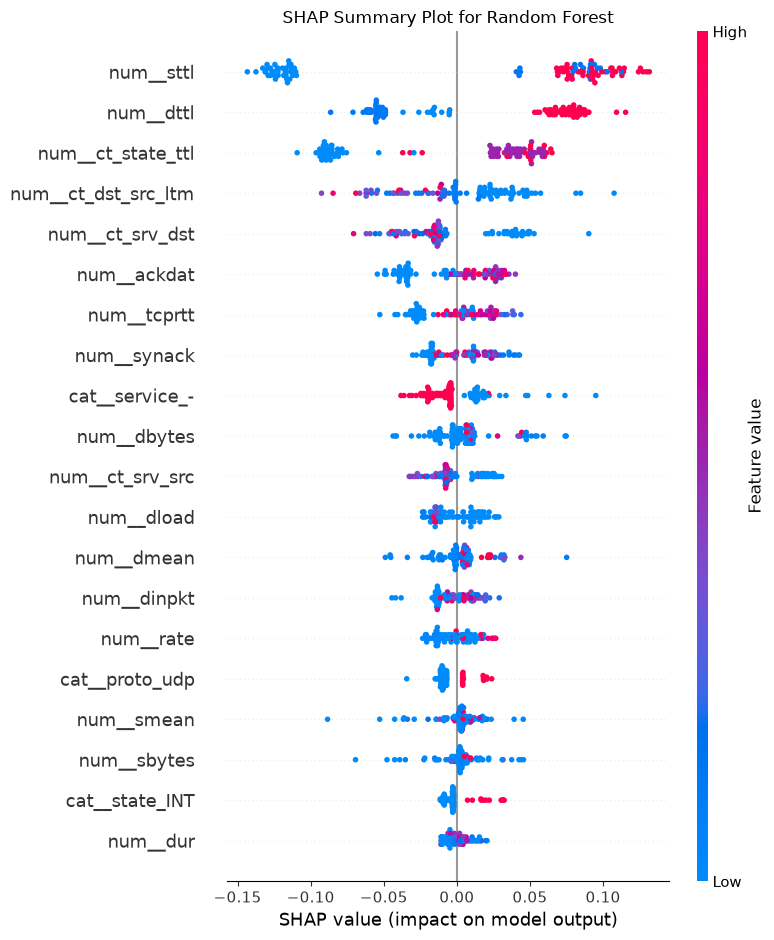

Top 10 features by mean absolute SHAP value:


,Feature,Mean |SHAP value|
0,num__sttl,0.101471
1,num__dttl,0.061466
2,num__ct_state_ttl,0.058696
3,num__ct_dst_src_ltm,0.030663
4,num__ct_srv_dst,0.028148
5,num__ackdat,0.024328
6,num__tcprtt,0.020514
7,num__synack,0.017362
8,cat__service_-,0.016092
9,num__dbytes,0.015604


In [50]:
import shap

# Use the trained Random Forest model from Part B for SHAP analysis
rf_pipeline = models["Random Forest"]

# Extract the classifier and preprocessor from the pipeline for SHAP analysis
rf_model = rf_pipeline.named_steps["clf"]
rf_preprocessor = rf_pipeline.named_steps["prep"]

X_shap_raw = X_val.sample(n=100, random_state=SEED)  # Use a sample for SHAP to speed up computation
X_shap = rf_preprocessor.transform(X_shap_raw)  # Apply the same preprocessing to the SHAP sample

if hasattr(X_shap, "toarray"):
    X_shap = X_shap.toarray()  # Convert sparse matrix to dense if necessary

# Get feature names after preprocessing
feature_names = rf_preprocessor.get_feature_names_out()

# Compute SHAP values for the Random Forest model
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_shap)

print("SHAP shape:", np.asarray(shap_values).shape)

# Select SHAP values for the attack class (1)
if isinstance(shap_values, list):
    attack_shap_values = shap_values[1]
else:
    attack_shap_values = shap_values[:, :, 1]

print("Attack SHAP shape:", np.asarray(attack_shap_values).shape)

# Generate the SHAP summary plot for the attack class
shap.summary_plot(
    attack_shap_values,
    X_shap,
    feature_names=feature_names,
    show=False
)

plt.title("SHAP Summary Plot for Random Forest")
plt.tight_layout()
plt.savefig(RESULTS / "shap_summary_plot.png", dpi=150, bbox_inches="tight")
plt.show()

# Display the top 10 features by mean absolute SHAP value
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean |SHAP value|": np.mean(np.abs(attack_shap_values), axis=0)
}).sort_values(by="Mean |SHAP value|", ascending=False)
print("Top 10 features by mean absolute SHAP value:")
display(shap_importance.head(10).reset_index(drop=True))

### D1b. Do the models agree on the important features?
We compare the top 10 features of each model: impurity importance for the Decision Tree, absolute coefficients for Logistic Regression, and mean |SHAP| for the three Random Forests from Parts B and C, all on the same 100 validation flows.

In [51]:
def clean_feature_names(pipeline):
    """Feature names after preprocessing, without the 'num__'/'cat__' prefix."""
    names = pipeline.named_steps["prep"].get_feature_names_out()
    return [n.split("__", 1)[1] for n in names]

def shap_top10(pipeline, X_sample):
    """Top 10 features by mean |SHAP| for the attack class."""
    X_t = pipeline.named_steps["prep"].transform(X_sample)
    if hasattr(X_t, "toarray"):
        X_t = X_t.toarray()
    values = shap.TreeExplainer(pipeline.named_steps["clf"]).shap_values(X_t)
    values = values[1] if isinstance(values, list) else values[:, :, 1]
    importance = pd.Series(np.abs(values).mean(axis=0), index=clean_feature_names(pipeline))
    return importance.sort_values(ascending=False).index[:10]

def tree_top10(pipeline):
    """Top 10 features by impurity-based importance."""
    importance = pd.Series(pipeline.named_steps["clf"].feature_importances_,
                           index=clean_feature_names(pipeline))
    return importance.sort_values(ascending=False).index[:10]

def logreg_top10(pipeline):
    """Top 10 features by absolute coefficient (inputs are scaled, so they are comparable)."""
    weights = pd.Series(pipeline.named_steps["clf"].coef_[0], index=clean_feature_names(pipeline))
    return weights.abs().sort_values(ascending=False).index[:10]

top_feature_lists = pd.DataFrame({
    "Decision Tree": tree_top10(models["Decision Tree"]),
    "Logistic Regression": logreg_top10(models["Logistic Regression"]),
    "SHAP forest (100%)": shap_top10(models["Random Forest"], X_shap_raw),
    "SHAP forest (10%)": shap_top10(rf_small, X_shap_raw),
    "SHAP forest (pseudo)": shap_top10(rf_semi, X_shap_raw),
}, index=range(1, 11))
top_feature_lists.index.name = "Rank"

display(top_feature_lists)

,Decision Tree,Logistic Regression,SHAP forest (100%),SHAP forest (10%),SHAP forest (pseudo)
Rank,,,,,
1,sttl,dttl,sttl,sttl,sttl
2,ct_dst_src_ltm,dload,dttl,dttl,dttl
3,ct_srv_dst,proto_tcp,ct_state_ttl,ct_state_ttl,ct_state_ttl
4,service_dns,dpkts,ct_dst_src_ltm,ct_dst_src_ltm,ackdat
5,sbytes,dbytes,ct_srv_dst,ct_srv_dst,ct_srv_dst
6,smean,state_FIN,ackdat,tcprtt,tcprtt
7,ct_state_ttl,sbytes,tcprtt,ackdat,ct_dst_src_ltm
8,dmean,proto_udp,synack,synack,synack
9,sload,state_CON,service_-,ct_srv_src,dinpkt


### D2. Local explanation using SHAP and LIME
We're using three validation flows to examine predictions. We're using a confident attack, a confident normal flow, and a misclassified flow.
Both SHAP and LIME will be used to explain the same three flows.

,Case,True Label,Predicted Label,Predicted Probability,Confidence
94822,Correct Attack,1,1,1.000,1.000
113256,Correct Normal,0,0,0.000,1.000
89480,Mistake,1,0,0.005,0.995



Correct Attack


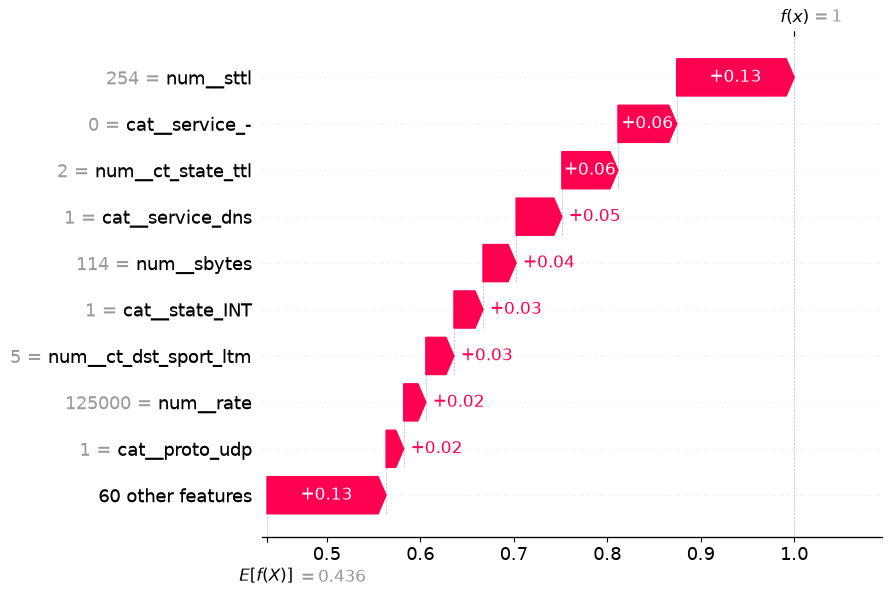


Correct Normal


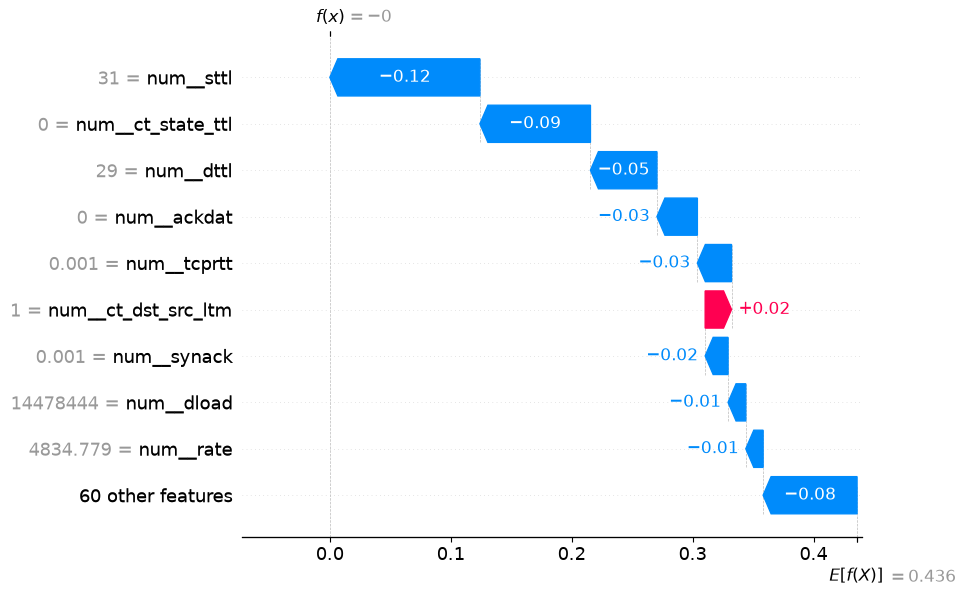


Mistake


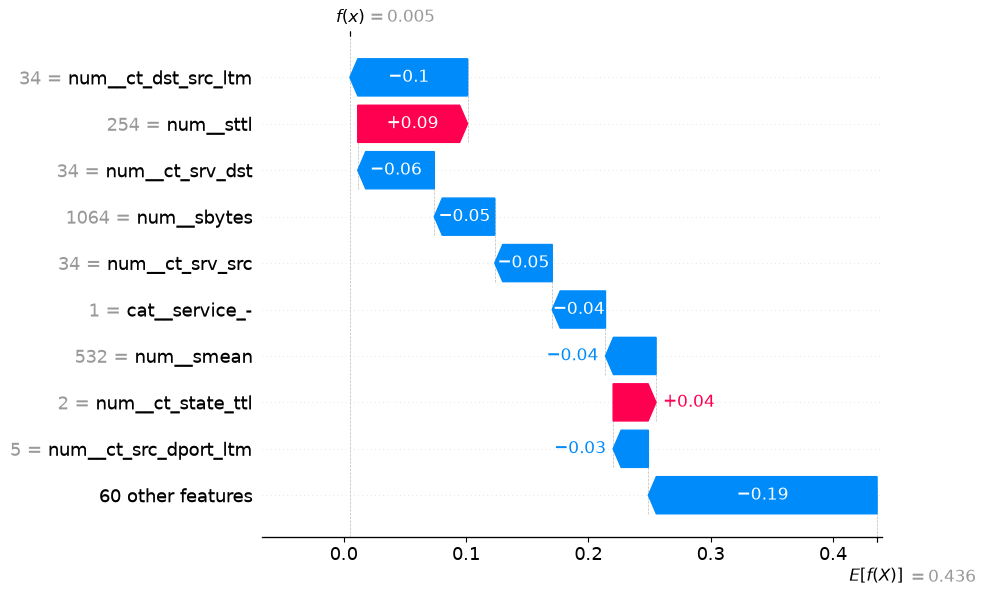


LIME Explanation for Correct Attack
LIME R² for Correct Attack: 0.587


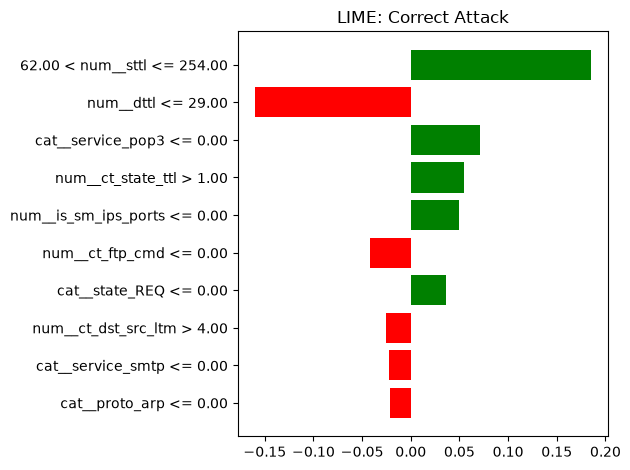


LIME Explanation for Correct Normal
LIME R² for Correct Normal: 0.908


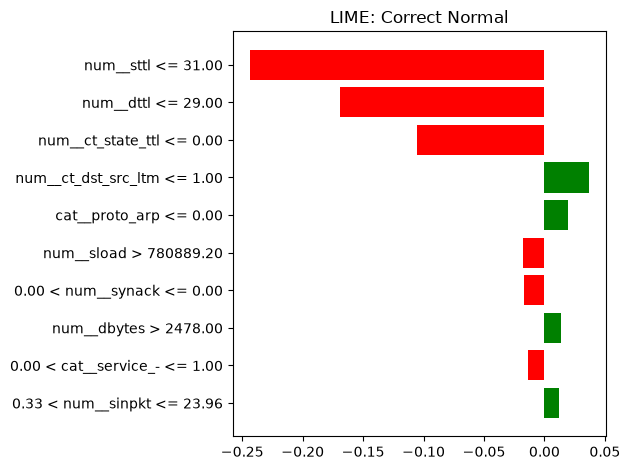


LIME Explanation for Mistake
LIME R² for Mistake: 0.585


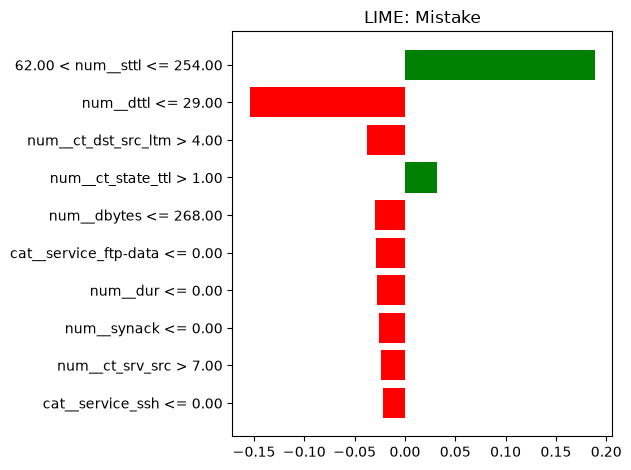

In [52]:
# Predictions from the random forest
val_prob = rf_pipeline.predict_proba(X_val)[:, 1]
val_pred = rf_pipeline.predict(X_val)

# Store the predictions and probabilities in a DataFrame for further analysis
val_results = pd.DataFrame({
    "True Label": y_val,
    "Predicted Label": val_pred,
    "Predicted Probability": val_prob
})

# Confidence in the predicted class
val_results["Confidence"] = np.where(val_results["Predicted Label"] == 1, val_results["Predicted Probability"], 1 - val_results["Predicted Probability"])

# Select one flow of each type
correct_attack = val_results[(val_results["True Label"] == 1) & (val_results["Predicted Label"] == 1)].nlargest(1, "Confidence")
correct_normal = val_results[(val_results["True Label"] == 0) & (val_results["Predicted Label"] == 0)].nlargest(1, "Confidence")
mistake = val_results[(val_results["True Label"] == 1) & (val_results["Predicted Label"] == 0)].nlargest(1, "Confidence")

selected_indices = {
    "Correct Attack": correct_attack.index[0],
    "Correct Normal": correct_normal.index[0],
    "Mistake": mistake.index[0]
}

selected_cases = val_results.loc[list(selected_indices.values())].copy()
selected_cases.insert(0, "Case", list(selected_indices.keys()))

display(selected_cases)

# Generate SHAP explanations for the three cases
X_local = rf_preprocessor.transform(X_val.loc[list(selected_indices.values())])

# Convert to dense array if necessary
if hasattr(X_local, "toarray"):
    X_local = X_local.toarray()

# Get SHAP values for the selected cases
local_shap = explainer.shap_values(X_local)
local_attack_shap = local_shap[1] if isinstance(local_shap, list) else local_shap[:, :, 1]

# Generate waterfall plots for the selected cases
for i, case in enumerate(selected_indices):
    print(f"\n{case}")

    explanation = shap.Explanation(
        values=local_attack_shap[i],
        base_values=explainer.expected_value[1],
        data=X_local[i],
        feature_names=feature_names
    )

    shap.plots.waterfall(explanation, max_display=10)

# Prepare a sample of the training data for LIME explanations
X_lime_train = rf_preprocessor.transform(X_train.sample(n=1000, random_state=SEED))

if hasattr(X_lime_train, "toarray"):
    X_lime_train = X_lime_train.toarray()  # Convert sparse matrix to dense if necessary

# Create a LIME explainer using the training data sample
lime_explainer = LimeTabularExplainer(
    X_lime_train,
    feature_names=feature_names,
    class_names=["Normal", "Attack"],
    mode="classification",
    random_state=SEED
)

# Generate LIME explanations for the selected cases
for i, case in enumerate(selected_indices):
    print(f"\nLIME Explanation for {case}")

    lime_exp = lime_explainer.explain_instance(
        X_local[i],
        rf_model.predict_proba,
        num_features=10,
        num_samples=1000
    )

    # Check how well the local LIME model approximates Random Forest
    print(f"LIME R² for {case}: {lime_exp.score:.3f}")

    # Display the LIME explanation as a matplotlib figure
    lime_exp.as_pyplot_figure(label=1)
    plt.title(f"LIME: {case}")
    plt.tight_layout()
    plt.show()


### D3. SHAP Fidelity Test

In [53]:
# Compute feature medians from the training data
X_train_transformed = rf_preprocessor.transform(X_train)

if hasattr(X_train_transformed, "toarray"):
    X_train_transformed = X_train_transformed.toarray()

train_medians = np.median(X_train_transformed, axis=0)

# Original attack probabilities
original_probs = rf_model.predict_proba(X_shap)[:, 1]

rng = np.random.default_rng(SEED)
fidelity_results = []

# Compare replacing 1, 3, and 5 features
for k in [1, 3, 5]:
    X_top = X_shap.copy()
    X_random = X_shap.copy()

    for i in range(len(X_shap)):
        top_idx = np.argsort(np.abs(attack_shap_values[i]))[-k:]
        random_idx = rng.choice(X_shap.shape[1], size=k, replace=False)

        X_top[i, top_idx] = train_medians[top_idx]
        X_random[i, random_idx] = train_medians[random_idx]

    top_probs = rf_model.predict_proba(X_top)[:, 1]
    random_probs = rf_model.predict_proba(X_random)[:, 1]

    fidelity_results.append({
        "Features replaced": k,
        "Top SHAP change": np.mean(np.abs(original_probs - top_probs)),
        "Random change": np.mean(np.abs(original_probs - random_probs))
    })

display(pd.DataFrame(fidelity_results).round(4))

,Features replaced,Top SHAP change,Random change
0,1,0.1606,0.0168
1,3,0.3418,0.0321
2,5,0.3696,0.0577


### D4. LIME stability test

In [54]:
from itertools import combinations

# Test LIME stability using five different random seeds
stability_results = []

for i, case in enumerate(selected_indices):
    top_features = []

    for seed in range(SEED, SEED + 5):
        lime = LimeTabularExplainer(
            X_lime_train,
            feature_names=feature_names,
            class_names=["Normal", "Attack"],
            mode="classification",
            random_state=seed
        )

        exp = lime.explain_instance(
            X_local[i],
            rf_model.predict_proba,
            num_features=3,
            num_samples=1000
        )

        top3 = [feature_names[j] for j, _ in exp.as_map()[1][:3]]
        top_features.append(set(top3))

        stability_results.append({
            "Case": case,
            "Seed": seed,
            "Top 3 features": ", ".join(top3)
        })

    # Average overlap between all pairs of runs
    overlap = np.mean([
        len(a & b) / 3
        for a, b in combinations(top_features, 2)
    ])

    print(f"{case}: Mean top-3 overlap = {overlap:.3f}")

display(pd.DataFrame(stability_results))

Correct Attack: Mean top-3 overlap = 0.867
Correct Normal: Mean top-3 overlap = 1.000
Mistake: Mean top-3 overlap = 0.800


,Case,Seed,Top 3 features
0,Correct Attack,42,"num__sttl, num__dttl, num__ct_state_ttl"
1,Correct Attack,43,"num__sttl, num__dttl, cat__proto_udp"
2,Correct Attack,44,"num__sttl, num__dttl, num__ct_state_ttl"
3,Correct Attack,45,"num__sttl, num__dttl, num__ct_state_ttl"
4,Correct Attack,46,"num__sttl, num__dttl, num__ct_state_ttl"
5,Correct Normal,42,"num__sttl, num__dttl, num__ct_state_ttl"
6,Correct Normal,43,"num__sttl, num__dttl, num__ct_state_ttl"
7,Correct Normal,44,"num__sttl, num__dttl, num__ct_state_ttl"
8,Correct Normal,45,"num__sttl, num__dttl, num__ct_state_ttl"
9,Correct Normal,46,"num__sttl, num__dttl, num__ct_state_ttl"


## Part E

### Missing Features

Macro-F1         Attack recall          \
                                         mean     std          mean     std   
Missing fraction Model                                                        
0.000000         Decision Tree         0.8908  0.0000        0.8781  0.0000   
                 Logistic Regression   0.8542  0.0000        0.9290  0.0000   
                 Random Forest         0.9164  0.0000        0.9032  0.0000   
0.095238         Decision Tree         0.8253  0.0016        0.8545  0.0024   
                 Logistic Regression   0.7958  0.0015        0.7640  0.0028   
                 Random Forest         0.8951  0.0008        0.9256  0.0006   
0.190476         Decision Tree         0.7672  0.0027        0.8334  0.0033   
                 Logistic Regression   0.7415  0.0018        0.6224  0.0046   
                 Random Forest         0.8618  0.0010        0.9363  0.0012   
0.309524         Decision Tree         0.7060  0.0019        0.8127  0.0043   
                 Logistic Regression   0.6764  0.0010        0.4726  0.0028   
                 Random Forest         0.8180  0.0010        0.9351  0.0012   
0.500000         Decision Tree         0.6205  0.0031        0.7865  0.0063   
                 Logistic Regression   0.5731  0.0022        0.2744  0.0021   
                 Random Forest         0.7414  0.0012        0.9247  0.0016   
0.690476         Decision Tree         0.5346  0.0023        0.7758  0.0051   
                 Logistic Regression   0.4679  0.0022        0.1191  0.0025   
                 Random Forest         0.6371  0.0036        0.9331  0.0015   

                                         FAR          
                                        mean     std  
Missing fraction Model                                
0.000000         Decision Tree        0.0963  0.0000  
                 Logistic Regression  0.2030  0.0000  
                 Random Forest        0.0709  0.0000  
0.095238         Decision Tree        0.1953  0.0029  
                 Logistic Regression  0.1732  0.0011  
                 Random Forest        0.1271  0.0015  
0.190476         Decision Tree        0.2833  0.0035  
                 Logistic Regression  0.1462  0.0013  
                 Random Forest        0.1952  0.0016  
0.309524         Decision Tree        0.3765  0.0013  
                 Logistic Regression  0.1171  0.0011  
                 Random Forest        0.2724  0.0014  
0.500000         Decision Tree        0.5051  0.0029  
                 Logistic Regression  0.0730  0.0017  
                 Random Forest        0.3985  0.0020  
0.690476         Decision Tree        0.6371  0.0009  
                 Logistic Regression  0.0323  0.0015  
                 Random Forest        0.5739  0.0058

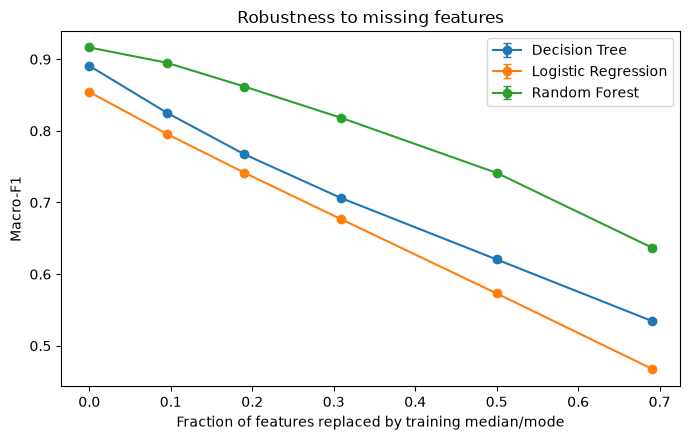

In [55]:
# Models to test for robustness
robust_models = {name: models[name] for name in ["Logistic Regression", "Decision Tree", "Random Forest"]}

# Replacement values, taken from the TRAINING data only:
# median for numeric features, most common value for categorical features
fill_values = pd.concat([X_train[numeric].median(), X_train[categorical].mode().iloc[0]])
all_cols = list(X_val.columns)
n, p = X_val.shape  # n = number of flows, p = number of features

missing_levels = [0, 0.1, 0.2, 0.3, 0.5, 0.7]  # share of features to hide
n_repeats = 5                                  # repeat to reduce randomness
records = []                                   # collects the results

for rep in range(n_repeats):
    rng = np.random.default_rng(SEED + rep)  # new seed for each repeat

    # Give each flow a random order of its features.
    # Higher levels hide more features from the same order,
    # so features hidden at 10% are also hidden at 30%.
    order = rng.random((n, p)).argsort(axis=1)

    for frac in missing_levels:
        k = int(round(frac * p))  # number of features to hide per flow

        X_miss = X_val.copy()  # work on a copy, keep the original data
        X_miss[numeric] = X_miss[numeric].astype(float)  # allow decimal medians

        if k > 0:
            # Mark the first k features in each flow's random order as missing
            mask = np.zeros((n, p), dtype=bool)
            mask[np.arange(n)[:, None], order[:, :k]] = True

            # Replace the marked values with the training median/mode
            for j, col in enumerate(all_cols):
                X_miss.loc[mask[:, j], col] = fill_values[col]

        # Evaluate each model on the modified data
        for name, model in robust_models.items():
            pred = model.predict(X_miss)
            prob = model.predict_proba(X_miss)[:, 1]  # probability of attack
            records.append({"Repeat": rep, "Missing fraction": k / p, "Model": name,
                            **scores(y_val, pred, prob)})

# Collect all results and average over the repeats
missing_results = pd.DataFrame(records)
summary = (missing_results
           .groupby(["Missing fraction", "Model"])[["Macro-F1", "Attack recall", "FAR"]]
           .agg(["mean", "std"]))
display(summary.round(4))

# Plot Macro-F1 against the share of hidden features, one line per model
plt.figure(figsize=(7, 4.5))
for name, group in summary["Macro-F1"].reset_index().groupby("Model"):
    plt.errorbar(group["Missing fraction"], group["mean"], yerr=group["std"],
                 marker="o", capsize=3, label=name)
plt.xlabel("Fraction of features replaced by training median/mode")
plt.ylabel("Macro-F1")
plt.title("Robustness to missing features")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "robustness_missing.png", dpi=150, bbox_inches="tight")
plt.show()

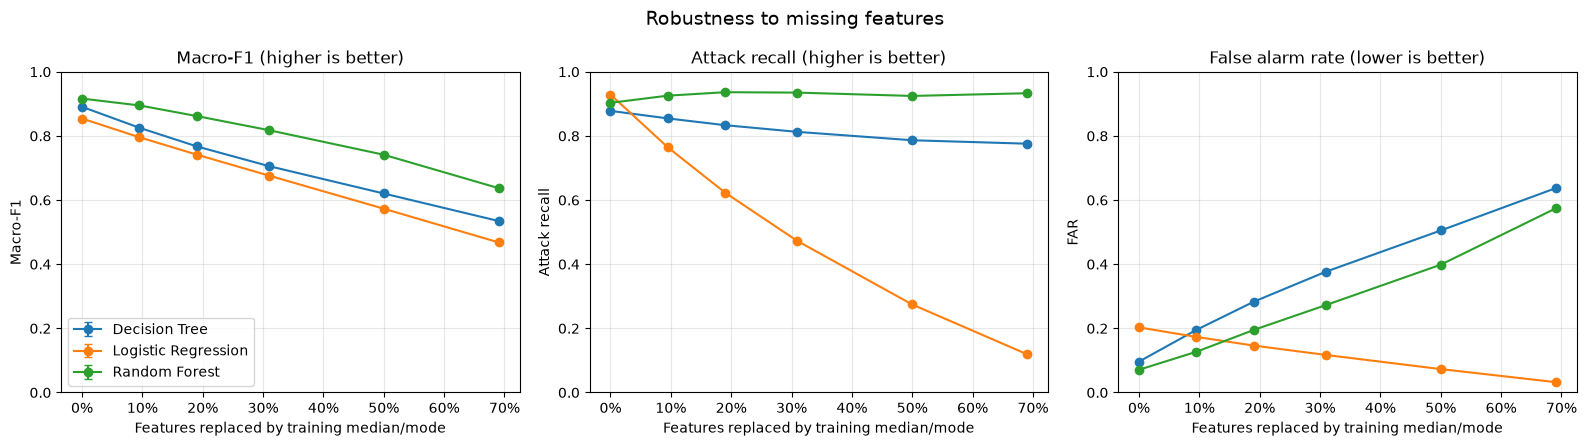

In [56]:
from matplotlib.ticker import PercentFormatter

metrics = ["Macro-F1", "Attack recall", "FAR"]
titles = {"Macro-F1": "Macro-F1 (higher is better)",
          "Attack recall": "Attack recall (higher is better)",
          "FAR": "False alarm rate (lower is better)"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)

for ax, metric in zip(axes, metrics):
    metric_df = summary[metric].reset_index()
    for name, group in metric_df.groupby("Model"):
        ax.errorbar(group["Missing fraction"], group["mean"], yerr=group["std"],
                    marker="o", capsize=3, label=name)
    ax.set_title(titles[metric])
    ax.set_xlabel("Features replaced by training median/mode")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(alpha=0.3)

axes[0].legend()
fig.suptitle("Robustness to missing features", fontsize=14)
fig.tight_layout()
fig.savefig(RESULTS / "robustness_missing_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

## Part F

## Part F — A knowledge-based layer (Belief Rule Base)

### F1. Choosing referential values
The BRB uses the two most important features from Part D: `sttl` and `dttl`.
Before choosing three referential values (Low, Medium, High) for each, we look at how the values
are distributed in the training set, overall and per class. Only training data is used.


=== sttl ===
Distinct values: 13
Min / median / max: 0 / 62.0 / 255
Top 10 values (share of training rows, attack share among them):


,Flows,Attack_share,Share of rows (%)
value,,,
254,41773,0.675,46.03
31,33530,0.000,36.95
62,14817,0.765,16.33
0,475,0.000,0.52
1,51,0.000,0.06
29,31,0.000,0.03
63,20,0.000,0.02
255,19,0.895,0.02
32,10,0.000,0.01



=== dttl ===
Distinct values: 9
Min / median / max: 0 / 29.0 / 254
Top 10 values (share of training rows, attack share among them):


,Flows,Attack_share,Share of rows (%)
value,,,
252,44581,0.699,49.13
29,33508,0.000,36.93
0,12352,0.663,13.61
60,242,0.806,0.27
30,27,0.000,0.03
31,22,0.000,0.02
253,5,1.000,0.01
32,4,0.000,0.00
254,2,0.000,0.00


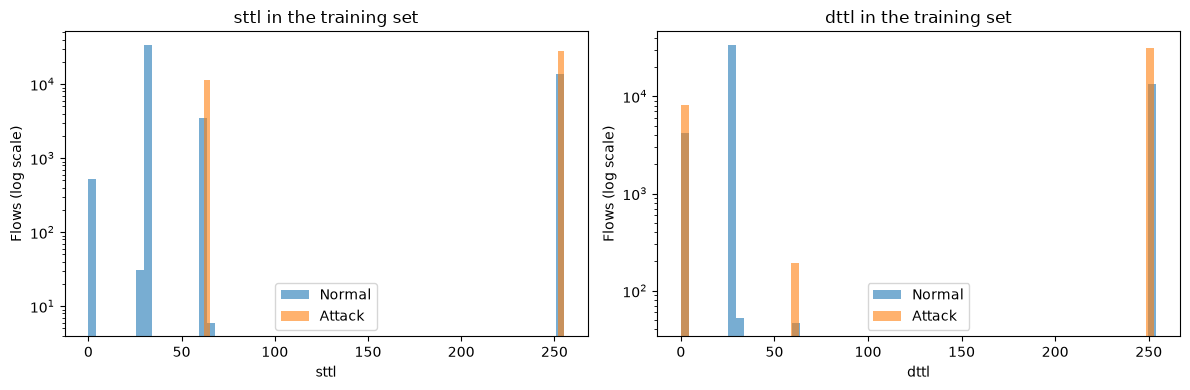

In [57]:
BRB_FEATURES = ["sttl", "dttl"]

for feat in BRB_FEATURES:
    values = X_train[feat]
    print(f"\n=== {feat} ===")
    print(f"Distinct values: {values.nunique()}")
    print(f"Min / median / max: {values.min()} / {values.median()} / {values.max()}")

    # The most common values and how often each is an attack
    counts = (pd.DataFrame({"value": values, "label": y_train})
                .groupby("value")["label"]
                .agg(Flows="size", Attack_share="mean")
                .sort_values("Flows", ascending=False))
    counts["Share of rows (%)"] = (100 * counts["Flows"] / len(values)).round(2)
    print("Top 10 values (share of training rows, attack share among them):")
    display(counts.head(10).round(3))

# Side-by-side histograms per class
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, feat in zip(axes, BRB_FEATURES):
    for lab, name in [(0, "Normal"), (1, "Attack")]:
        ax.hist(X_train.loc[y_train == lab, feat], bins=60, alpha=0.6, label=name)
    ax.set_yscale("log")
    ax.set_title(f"{feat} in the training set")
    ax.set_xlabel(feat)
    ax.set_ylabel("Flows (log scale)")
    ax.legend()
plt.tight_layout()
plt.show()

### F2. Referential values and matching degrees
Each feature gets three referential values: the three most frequent values in the training set (sorted as Low, Medium, High). F1 shows that these values cover about 99% of training flows and have very different attack shares (e.g. sttl = 31 is never an attack, sttl = 62 is an attack 77% of the time), so placing the referential values exactly on them keeps that information. Values outside the range are mapped to the nearest end (Low or High). Values in between are split between the two nearest referential values in proportion to their distance (the matching degree). A missing value gets matching degree 0 for all three, which is how the BRB represents missing information.


In [58]:
LEVELS = ["Low", "Medium", "High"]

def choose_anchors(values, k=3):
    """Low/Medium/High = the k most frequent training values, sorted (training data only)."""
    anchors = sorted(values.value_counts().index[:k].astype(float))
    coverage = values.isin(anchors).mean()
    return anchors, coverage

ANCHORS = {}
for feat in BRB_FEATURES:
    ANCHORS[feat], cov = choose_anchors(X_train[feat])
    print(f"{feat}: " + ", ".join(f"{lvl} = {v:g}" for lvl, v in zip(LEVELS, ANCHORS[feat]))
          + f"  (exact matches cover {cov:.1%} of training rows)")

def matching_degrees(x, anchors):
    """Belief of each value in Low/Medium/High (piecewise linear). Rows sum to 1, or 0 if missing."""
    x = np.asarray(x, dtype=float)
    m = np.column_stack([np.interp(x, anchors, np.eye(3)[k]) for k in range(3)])
    m[np.isnan(x)] = 0.0   # missing input: no belief in any referential value
    return m

# Example: how a few values are transformed
example_values = pd.Series([ANCHORS["sttl"][0], np.mean(ANCHORS["sttl"][:2]),
                            ANCHORS["sttl"][1], ANCHORS["sttl"][2], np.nan])
display(pd.DataFrame(matching_degrees(example_values, ANCHORS["sttl"]), columns=LEVELS,
                     index=[f"sttl = {v:g}" for v in example_values]).round(3))

sttl: Low = 31, Medium = 62, High = 254  (exact matches cover 99.3% of training rows)
dttl: Low = 0, Medium = 29, High = 252  (exact matches cover 99.7% of training rows)


,Low,Medium,High
sttl = 31,1.0,0.0,0.0
sttl = 46.5,0.5,0.5,0.0
sttl = 62,0.0,1.0,0.0
sttl = 254,0.0,0.0,1.0
sttl = nan,0.0,0.0,0.0


### F3. Nine rules with beliefs estimated from training data
Every combination of sttl level and dttl level gives one rule (3 × 3 = 9). Each rule's belief is
estimated from the training set: the attack share among the training flows that activate the rule,
weighted by how strongly they activate it. Rules supported by few flows keep part of their belief as
Unknown: completeness = support / (support + K). All rule weights and attribute weights are equal (1).

In [59]:
SUPPORT_K = 50   # a rule backed by 50 effective flows keeps half of its belief as Unknown

def rule_activation(X):
    """Matching degree of every flow in each of the 9 rules (rule k = sttl level i, dttl level j)."""
    m1 = matching_degrees(X["sttl"], ANCHORS["sttl"])
    m2 = matching_degrees(X["dttl"], ANCHORS["dttl"])
    # Input completeness: 1 when both features are present, 0.5 when one is missing
    completeness = (m1.sum(axis=1) + m2.sum(axis=1)) / 2
    # A missing feature activates its three levels equally (no information about it)
    m1 = np.where(m1.sum(axis=1, keepdims=True) == 0, 1 / 3, m1)
    m2 = np.where(m2.sum(axis=1, keepdims=True) == 0, 1 / 3, m2)
    alpha = (m1[:, :, None] * m2[:, None, :]).reshape(len(X), 9)
    return alpha, completeness

# Estimate the rule beliefs from the training set
alpha_train, _ = rule_activation(X_train)
support = alpha_train.sum(axis=0)                          # effective number of flows per rule
attack_share = np.divide(alpha_train.T @ y_train.to_numpy(), support,
                         out=np.zeros(9), where=support > 0)
rule_completeness = support / (support + SUPPORT_K)

# Belief distribution of each rule: [Normal, Attack]; the remainder is Unknown
RULE_BELIEFS = np.column_stack([rule_completeness * (1 - attack_share),
                                rule_completeness * attack_share])

rule_table = pd.DataFrame({
    "Rule": range(1, 10),
    "IF sttl is": [LEVELS[k // 3] for k in range(9)],
    "AND dttl is": [LEVELS[k % 3] for k in range(9)],
    "Support (flows)": support.round(0).astype(int),
    "Normal": RULE_BELIEFS[:, 0],
    "Attack": RULE_BELIEFS[:, 1],
    "Unknown": 1 - RULE_BELIEFS.sum(axis=1),
}).set_index("Rule")
print("Belief rule base (THEN part = belief in Normal / Attack / Unknown):")
display(rule_table.round(3))

Belief rule base (THEN part = belief in Normal / Attack / Unknown):


,IF sttl is,AND dttl is,Support (flows),Normal,Attack,Unknown
Rule,,,,,,
1,Low,Low,538,0.915,0.000,0.085
2,Low,Medium,33560,0.999,0.000,0.001
3,Low,High,0,0.009,0.000,0.991
4,Medium,Low,119,0.191,0.514,0.295
5,Medium,Medium,0,0.006,0.000,0.994
6,Medium,High,14731,0.235,0.761,0.003
7,High,Low,11694,0.305,0.690,0.004
8,High,Medium,208,0.157,0.650,0.194
9,High,High,29891,0.332,0.666,0.002


### F4. Combining the rules with Evidential Reasoning
For each flow, the activated rules are combined with the analytical Evidential Reasoning (ER)
algorithm. The output is a belief in Normal, a belief in Attack and an Unknown part. When an input is
missing, every rule's belief is scaled down by the input completeness before combining, so the missing
information ends up as Unknown instead of being guessed.

In [60]:
def brb_infer(X):
    """Return beliefs [Normal, Attack, Unknown] for every flow, plus the rule activation weights."""
    alpha, completeness = rule_activation(X)
    w = alpha / alpha.sum(axis=1, keepdims=True)                  # activation weights, sum to 1

    B = RULE_BELIEFS[None, :, :] * completeness[:, None, None]    # (flows, rules, 2) after input update
    BD = B.sum(axis=2)                                            # assigned belief per rule

    # Analytical ER algorithm (Wang, Yang & Xu, 2006)
    term = np.prod(w[:, :, None] * B + 1 - w[:, :, None] * BD[:, :, None], axis=1)  # (flows, 2)
    p_d = np.prod(1 - w * BD, axis=1)
    p_0 = np.prod(1 - w, axis=1)
    mu = 1 / (term.sum(axis=1) - (2 - 1) * p_d)
    beliefs = mu[:, None] * (term - p_d[:, None]) / (1 - mu * p_0)[:, None]
    unknown = 1 - beliefs.sum(axis=1)

    out = pd.DataFrame({"Normal": beliefs[:, 0], "Attack": beliefs[:, 1], "Unknown": unknown},
                       index=X.index)
    return out, w

brb_val, _ = brb_infer(X_val)
print("BRB belief output for the first five validation flows:")
display(brb_val.head().round(4))
print("Beliefs sum to 1 for every flow:", np.allclose(brb_val.sum(axis=1), 1))

BRB belief output for the first five validation flows:


,Normal,Attack,Unknown
41559,0.3323,0.6661,0.0017
113256,0.9985,0.0000,0.0015
94822,0.3054,0.6903,0.0043
46154,0.3323,0.6661,0.0017
149473,0.3054,0.6903,0.0043


Beliefs sum to 1 for every flow: True


### F5. Fair comparison on the same two features
A Decision Tree and a Random Forest are trained on only `sttl` and `dttl`, with the same settings
selected in Part B. All three are evaluated on the validation set with the same metrics. The BRB
predicts Attack when its belief in Attack exceeds its belief in Normal; its belief in Attack is used as
the score for PR-AUC. The full Random Forest from Part B (all 42 features) is shown as a reference.

In [61]:
def part_b_params(name):
    """Settings selected in Part B, without the pipeline prefix."""
    return {k.replace("clf__", ""): v for k, v in selected_settings[name].items()}

X_train_2 = X_train[BRB_FEATURES]
X_val_2 = X_val[BRB_FEATURES]

tree_2 = DecisionTreeClassifier(random_state=SEED, **part_b_params("Decision Tree")).fit(X_train_2, y_train)
forest_2 = RandomForestClassifier(n_jobs=-1, random_state=SEED,
                                  **part_b_params("Random Forest")).fit(X_train_2, y_train)

brb_pred = (brb_val["Attack"] > brb_val["Normal"]).astype(int).to_numpy()

brb_comparison = pd.DataFrame({
    "BRB (2 features, 9 rules)": scores(y_val, brb_pred, brb_val["Attack"].to_numpy()),
    "Decision Tree (2 features)": scores(y_val, tree_2.predict(X_val_2), tree_2.predict_proba(X_val_2)[:, 1]),
    "Random Forest (2 features)": scores(y_val, forest_2.predict(X_val_2), forest_2.predict_proba(X_val_2)[:, 1]),
    "Random Forest (all features, Part B)": validation["Random Forest"],
}).T
print("Validation results:")
display(brb_comparison.round(4))
print(f"Mean Unknown belief on validation flows: {brb_val['Unknown'].mean():.4f}")

Validation results:


,Accuracy,Macro-F1,Attack recall,PR-AUC (AP),FAR
"BRB (2 features, 9 rules)",0.8091,0.8084,1.0000,0.7186,0.3384
Decision Tree (2 features),0.8095,0.8088,0.9999,0.7215,0.3377
Random Forest (2 features),0.8095,0.8088,1.0000,0.7215,0.3377
"Random Forest (all features, Part B)",0.9178,0.9164,0.9032,0.9750,0.0709


Mean Unknown belief on validation flows: 0.0035


### F6. Belief output for one case
We use the attack flow that the Random Forest misclassified with high confidence in D2. We show
which rules fire and the BRB belief output, including the Unknown part. To show how the BRB handles
missing information, the same flow is also passed with `dttl` removed.

Flow 89480: true label = 1 (1 = attack)


,sttl,dttl
89480,254,0


Activated rules:


,Activation weight,IF sttl is,AND dttl is,Normal,Attack,Unknown
Rule,,,,,,
7,1.0,High,Low,0.305,0.69,0.004


Belief output:


,Normal,Attack,Unknown,Forest (2 features) P(attack),Forest (all features) P(attack)
Input,,,,,
Both features,0.3054,0.6903,0.0043,0.6932,0.005
dttl missing,0.1474,0.4010,0.4516,NaN,NaN


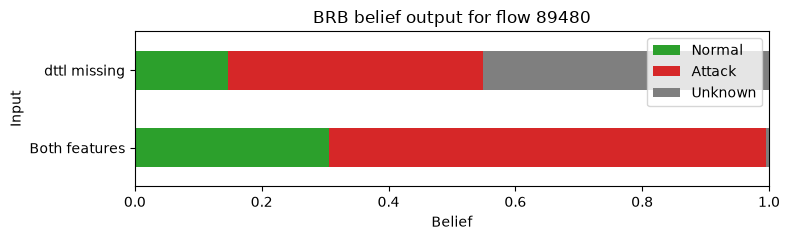

In [62]:
case_idx = selected_indices["Mistake"]          # misclassified attack flow from D2
case = X_val.loc[[case_idx], BRB_FEATURES]
print(f"Flow {case_idx}: true label = {y_val.loc[case_idx]} (1 = attack)")
display(case)

# Which rules fire and how strongly
case_beliefs, case_w = brb_infer(case)
active = rule_table.loc[case_w[0] > 0, ["IF sttl is", "AND dttl is", "Normal", "Attack", "Unknown"]].copy()
active.insert(0, "Activation weight", case_w[0][case_w[0] > 0])
print("Activated rules:")
display(active.round(3))

# Same flow with dttl missing
case_missing = case.copy()
case_missing["dttl"] = np.nan
missing_beliefs, _ = brb_infer(case_missing)

case_output = pd.concat([case_beliefs.assign(Input="Both features"),
                         missing_beliefs.assign(Input="dttl missing")]).set_index("Input")
case_output["Forest (2 features) P(attack)"] = [forest_2.predict_proba(case)[0, 1], np.nan]
case_output["Forest (all features) P(attack)"] = [rf_pipeline.predict_proba(X_val.loc[[case_idx]])[0, 1], np.nan]
print("Belief output:")
display(case_output.round(4))

# Stacked bars of the belief distribution
ax = case_output[["Normal", "Attack", "Unknown"]].plot.barh(stacked=True, figsize=(8, 2.5),
                                                            color=["tab:green", "tab:red", "tab:gray"])
ax.set_xlim(0, 1)
ax.set_xlabel("Belief")
ax.set_title(f"BRB belief output for flow {case_idx}")
plt.tight_layout()
plt.savefig(RESULTS / "brb_case.png", dpi=150, bbox_inches="tight")
plt.show()

### F7. What the BRB gives and what it costs

**What the BRB gives that the forest does not.**
- **A model you can read.** The whole BRB is the nine IF–THEN rules in F3. For example, rule 2 says *IF sttl is Low (31) AND dttl is Medium (29) THEN Normal 0.999*, and it covers 37% of the training traffic. An analyst can check, question or edit any rule. A forest of many trees cannot be read like that.
- **Uncertainty is shown explicitly.** The output is split into belief in Normal, belief in Attack and Unknown, and the Unknown part reflects how much evidence is behind a rule. Rules 3 and 5 match combinations that never occur in training, so they are about 99% Unknown. Rules 4 and 8 are backed by only 119 and 208 flows and keep 30% and 19% Unknown. A forest returns one probability that looks the same whether it rests on 30,000 flows or on 10.
- **Missing inputs are handled without guessing.** When dttl is removed from flow 89480, the BRB still leans towards Attack (0.40 vs 0.15 Normal), based on sttl alone, but moves 45% of its belief to Unknown, so the missing information is visible. The forest cannot make a prediction without imputing dttl first, and after imputation nothing in its output shows that a value was missing.
- **An explanation for each decision.** For flow 89480 the full forest was confidently wrong (P(attack) = 0.005). The BRB says Attack with belief 0.69 and shows why: only rule 7 fires (sttl High = 254, dttl Low = 0), and 69% of the training flows with that pattern are attacks. The two-feature forest gives the same probability (0.69), so the gain here is the explanation, not the accuracy. The reason this flow is caught is that the model sees only two features, not that it is a BRB.

**What it costs.**
- **No gain in accuracy, and a large loss compared with the full model.** On the same two features the BRB matches the tree and forest but does not beat them (Macro-F1 0.808 vs 0.809, PR-AUC 0.719 vs 0.722). All three are far below the full 42-feature forest (Macro-F1 0.916, PR-AUC 0.975, FAR 0.071 vs 0.338). The high FAR is a limit of the two TTL features, not of the BRB: about half of all flows have sttl = 254 and dttl = 252, and roughly a third of those are normal, so no model using only these two features can separate them.
- **It does not scale.** A complete rule base has 3ᵏ rules for k features with three referential values each. Two features give 9 rules, five give 243 and ten give about 59,000. The rules then become unreadable and most of them would have no training support. This is why the BRB is limited to two features.
- **More design choices made by hand.** The referential values, the support constant K = 50 and the decision rule (Attack if belief in Attack > belief in Normal) are set by us, and they change the rules and the Unknown part. A tree or forest chooses its own split points.
- **The knowledge here comes from data.** The rule beliefs are estimated from training frequencies, so they are only as good as the training labels. The structure would let an expert set or correct the beliefs, but that was not done here.
- **Unknown is rarely large in practice.** With both features present, the mean Unknown on the validation set is only 0.0035, because almost every flow falls on a well-supported rule. The Unknown part matters mostly for rare value combinations and missing inputs.

## Part G — Adaptability

### G1. Hide attack types from training
We simulate a new attack by removing every row of one attack category from the training set only.
The validation and test sets are unchanged. The Random Forest from Part B (same settings, no re-tuning)
is then retrained on the reduced training set, so it has never seen the hidden attack.
Each hidden type is a separate experiment: only one type is hidden at a time.

In [63]:
# Attack types to hide, one experiment per type. Chosen in advance by behaviour, not by results.
HIDDEN_TYPES = ["Fuzzers", "DoS", "Shellcode", "Exploits"]   # add "Shellcode" if runtime allows

hidden_models = {}   # one Random Forest per hidden attack type
hide_rows = []

for attack in HIDDEN_TYPES:
    t0 = time.perf_counter()

    # Keep every training row except the hidden attack type
    keep = cat_train != attack
    X_reduced, y_reduced = X_train[keep], y_train[keep]

    # Check that the hidden type is really gone from training
    assert (cat_train[keep] == attack).sum() == 0, f"{attack} still in training data"

    # Same black box as Part B (same settings), retrained without the hidden type
    model = clone(models["Random Forest"])
    model.fit(X_reduced, y_reduced)
    hidden_models[attack] = model

    hide_rows.append({
        "Hidden type": attack,
        "Removed from training": int((~keep).sum()),
        "Training rows left": len(X_reduced),
        "Hidden rows in test": int((cat_test == attack).sum()),
        "Fit time (s)": round(time.perf_counter() - t0, 1),
    })

print("Training sets with one attack type hidden:")
display(pd.DataFrame(hide_rows))

Training sets with one attack type hidden:


,Hidden type,Removed from training,Training rows left,Hidden rows in test,Fit time (s)
0,Fuzzers,11231,79512,3726,4.1
1,DoS,2191,88552,712,4.4
2,Shellcode,852,89891,301,4.6
3,Exploits,15230,75513,5178,3.6


### G2. Cost of an unseen attack
On the test set we compare the Part B Random Forest (trained on all attack types) with the model
that never saw the hidden type. We report overall attack recall and recall on the hidden type alone.
Recall on the remaining (known) attack types and the false alarm rate are added to show whether the
model got worse at what it already knew.

In [64]:
y_test_arr = y_test.to_numpy()
cat_test_arr = cat_test.to_numpy()
pred_full = models["Random Forest"].predict(X_test)   # reference: model that saw every attack type

def recall_breakdown(pred, attack):
    """Overall recall, recall on the hidden type, recall on the other attacks, and FAR."""
    is_hidden = cat_test_arr == attack
    is_known = (y_test_arr == 1) & ~is_hidden
    is_normal = y_test_arr == 0
    return {
        "Overall recall": recall_score(y_test_arr, pred),
        "Hidden-type recall": pred[is_hidden].mean(),   # share of hidden-type flows flagged as attack
        "Known-attack recall": pred[is_known].mean(),
        "FAR": pred[is_normal].mean(),                   # share of normal flows flagged as attack
    }

cost_rows = []
for attack in HIDDEN_TYPES:
    pred_hidden = hidden_models[attack].predict(X_test)
    cost_rows.append({"Hidden type": attack, "Model": "Full training (Part B)",
                      **recall_breakdown(pred_full, attack)})
    cost_rows.append({"Hidden type": attack, "Model": "Hidden from training",
                      **recall_breakdown(pred_hidden, attack)})

cost_table = pd.DataFrame(cost_rows).set_index(["Hidden type", "Model"])
print("Test-set recall with and without the hidden attack type in training:")
display(cost_table.round(4))

Test-set recall with and without the hidden attack type in training:


Overall recall  Hidden-type recall  \
Hidden type Model                                                        
Fuzzers     Full training (Part B)          0.9000              0.6978   
            Hidden from training            0.7315              0.1286   
DoS         Full training (Part B)          0.9000              0.9902   
            Hidden from training            0.8985              0.9747   
Shellcode   Full training (Part B)          0.9000              0.9701   
            Hidden from training            0.8985              0.9169   
Exploits    Full training (Part B)          0.9000              0.9799   
            Hidden from training            0.8859              0.9581   

                                    Known-attack recall     FAR  
Hidden type Model                                                
Fuzzers     Full training (Part B)               0.9797  0.0714  
            Hidden from training                 0.9690  0.0151  
DoS         Full training (Part B)               0.8949  0.0714  
            Hidden from training                 0.8941  0.0692  
Shellcode   Full training (Part B)               0.8984  0.0714  
            Hidden from training                 0.8981  0.0687  
Exploits    Full training (Part B)               0.8484  0.0714  
            Hidden from training                 0.8392  0.0606

### G3. Adapt with a few labelled examples
We assume an analyst has labelled 100 flows of the new attack. These are drawn at random from the
hidden type's rows in the training set (never from the test set), added to the reduced training set,
and the Random Forest is retrained with the same settings. The draw is repeated with three seeds.
We report recall on the hidden type before and after adapting.

In [65]:
N_LABELS = 100   # flows of the new attack labelled by the analyst
N_SEEDS = 3      # repeat the random draw to check it is not a lucky sample

adapt_rows = []
for attack in HIDDEN_TYPES:
    is_hidden_train = cat_train == attack
    X_reduced, y_reduced = X_train[~is_hidden_train], y_train[~is_hidden_train]

    # Pool of the hidden type's TRAINING rows; the test set is never used here
    pool = X_train[is_hidden_train]
    assert len(pool) >= N_LABELS, f"Only {len(pool)} training rows of {attack}"

    for seed in range(N_SEEDS):
        labelled = pool.sample(n=N_LABELS, random_state=SEED + seed)
        X_adapt = pd.concat([X_reduced, labelled])
        y_adapt = pd.concat([y_reduced, y_train.loc[labelled.index]])

        model = clone(models["Random Forest"])
        model.fit(X_adapt, y_adapt)
        adapt_rows.append({"Hidden type": attack, "Seed": seed,
                           **recall_breakdown(model.predict(X_test), attack)})

adapt_results = pd.DataFrame(adapt_rows)
adapt_summary = adapt_results.drop(columns="Seed").groupby("Hidden type").agg(["mean", "std"])

# Before = never saw the attack (G2), after = 100 labelled flows added
gain_rows = []
for attack in HIDDEN_TYPES:
    before = cost_table.loc[(attack, "Hidden from training")]
    full = cost_table.loc[(attack, "Full training (Part B)")]
    after = adapt_summary.loc[attack]
    gain_rows.append({
        "Hidden type": attack,
        "Hidden recall: full training": full["Hidden-type recall"],
        "Hidden recall: before": before["Hidden-type recall"],
        "Hidden recall: after (mean)": after[("Hidden-type recall", "mean")],
        "Hidden recall: after (std)": after[("Hidden-type recall", "std")],
        "Gain": after[("Hidden-type recall", "mean")] - before["Hidden-type recall"],
        "Overall recall: before": before["Overall recall"],
        "Overall recall: after": after[("Overall recall", "mean")],
        "FAR: after": after[("FAR", "mean")],
    })

gain_table = pd.DataFrame(gain_rows).set_index("Hidden type")
print(f"Effect of adding {N_LABELS} labelled flows of the hidden type ({N_SEEDS} seeds):")
display(gain_table.round(4))

Effect of adding 100 labelled flows of the hidden type (3 seeds):


,Hidden recall: full training,Hidden recall: before,Hidden recall: after (mean),Hidden recall: after (std),Gain,Overall recall: before,Overall recall: after,FAR: after
Hidden type,,,,,,,,
Fuzzers,0.6978,0.1286,0.1334,0.0012,0.0048,0.7315,0.7329,0.0156
DoS,0.9902,0.9747,0.9803,0.0028,0.0056,0.8985,0.8985,0.0691
Shellcode,0.9701,0.9169,0.9347,0.0084,0.0177,0.8985,0.8976,0.0686
Exploits,0.9799,0.9581,0.9573,0.0002,-0.0008,0.8859,0.8862,0.0605


In [66]:
# One table: full model, hidden model, and hidden model + 100 labelled flows (mean over seeds)
metric_cols = ["Overall recall", "Hidden-type recall", "Known-attack recall", "FAR"]

combined_rows = []
for attack in HIDDEN_TYPES:
    for model_name in ["Full training (Part B)", "Hidden from training"]:
        combined_rows.append({"Hidden type": attack, "Model": model_name,
                              **cost_table.loc[(attack, model_name)].to_dict()})
    adapted_mean = adapt_results[adapt_results["Hidden type"] == attack][metric_cols].mean()
    combined_rows.append({"Hidden type": attack, "Model": f"Hidden + {N_LABELS} labels",
                          **adapted_mean.to_dict()})

combined_table = pd.DataFrame(combined_rows).set_index(["Hidden type", "Model"])[metric_cols]
print(f"Test-set results before and after adding {N_LABELS} labelled flows "
      f"(adapted rows are the mean of {N_SEEDS} seeds):")
display(combined_table.round(4))

# Spread of the adapted hidden-type recall across seeds, to report alongside the table
display(adapt_results.groupby("Hidden type")["Hidden-type recall"]
        .agg(["mean", "std"]).round(4).rename(columns={"mean": "Adapted recall (mean)",
                                                        "std": "Std over seeds"}))

Test-set results before and after adding 100 labelled flows (adapted rows are the mean of 3 seeds):


Overall recall  Hidden-type recall  \
Hidden type Model                                                        
Fuzzers     Full training (Part B)          0.9000              0.6978   
            Hidden from training            0.7315              0.1286   
            Hidden + 100 labels             0.7329              0.1334   
DoS         Full training (Part B)          0.9000              0.9902   
            Hidden from training            0.8985              0.9747   
            Hidden + 100 labels             0.8985              0.9803   
Shellcode   Full training (Part B)          0.9000              0.9701   
            Hidden from training            0.8985              0.9169   
            Hidden + 100 labels             0.8976              0.9347   
Exploits    Full training (Part B)          0.9000              0.9799   
            Hidden from training            0.8859              0.9581   
            Hidden + 100 labels             0.8862              0.9573   

                                    Known-attack recall     FAR  
Hidden type Model                                                
Fuzzers     Full training (Part B)               0.9797  0.0714  
            Hidden from training                 0.9690  0.0151  
            Hidden + 100 labels                  0.9691  0.0156  
DoS         Full training (Part B)               0.8949  0.0714  
            Hidden from training                 0.8941  0.0692  
            Hidden + 100 labels                  0.8938  0.0691  
Shellcode   Full training (Part B)               0.8984  0.0714  
            Hidden from training                 0.8981  0.0687  
            Hidden + 100 labels                  0.8967  0.0686  
Exploits    Full training (Part B)               0.8484  0.0714  
            Hidden from training                 0.8392  0.0606  
            Hidden + 100 labels                  0.8403  0.0605

,Adapted recall (mean),Std over seeds
Hidden type,,
DoS,0.9803,0.0028
Exploits,0.9573,0.0002
Fuzzers,0.1334,0.0012
Shellcode,0.9347,0.0084
